# Lab — Visual Foundation Models

Nos slides, um *foundation model* é um modelo pré-treinado em muitos dados sem rótulo, com aprendizado auto-supervisionado, cuja representação serve para várias tarefas diferentes. Nesta aula não treinamos nenhum desses modelos (isso custa centenas de GPUs): pegamos versões pré-treinadas do Hugging Face e abrimos cada uma por dentro, na ordem dos slides:

1. **ViT:** vocês escrevem o **patch embedding** (TODO 1) e a **interpolação dos position embeddings** para usar o modelo numa resolução maior (TODO 2).
2. **Swin:** vocês escrevem a **partição em janelas, com e sem shift** (TODO 3) e vemos o mapa de características hierárquico.
3. **MAE:** vocês escrevem o **random masking** (TODO 4), plugam no MAE pré-treinado e veem o que ele reconstrói com 75%, 85% e 95% da imagem escondida.
4. **Supervisionado × MAE × DINO × MSN:** comparamos as representações com pouquíssimos rótulos e vemos para onde cada modelo "olha".
5. **SAM:** segmentação por prompt (pontos e caixas), ambiguidade e o custo do encoder × decoder.
6. **Matcher:** vocês escrevem o **casamento bidirecional de patches** (TODO 5) e montamos um segmentador *one-shot*, sem treino nenhum, juntando DINOv2 e SAM.

**Como usar:** rode as células em ordem. Os trechos que vocês devem completar estão marcados com `# TODO`, e logo depois há uma célula de teste. Use GPU no Colab (*Ambiente de execução → Alterar tipo*). Os modelos somam uns 2,5 GB de download; nenhuma célula demora mais que um ou dois minutos.

## 0. Setup

device: cuda


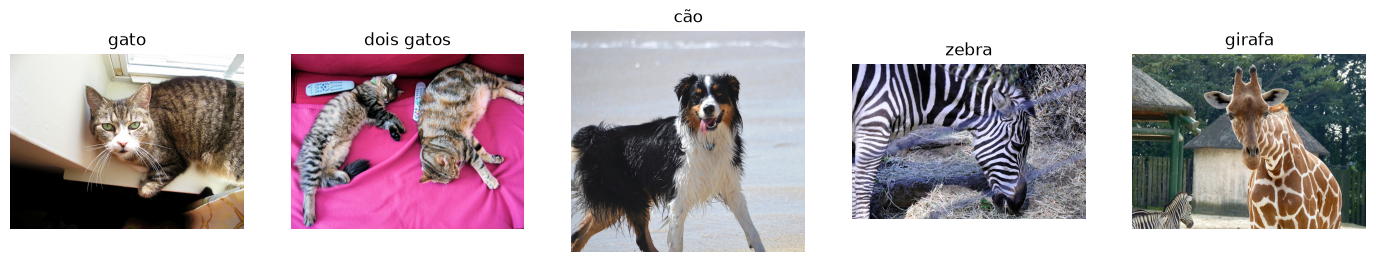

In [1]:
import io, math, time, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()             # esconde os avisos de carregamento dos modelos
hf_logging.disable_progress_bar()            # e as barras de progresso
torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)   # normalização do ImageNet,
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)    # a mesma em todos os modelos da aula


def load_image(coco_id):
    """Baixa uma imagem do conjunto de validação do COCO 2017."""
    with urllib.request.urlopen(f"http://images.cocodataset.org/val2017/{coco_id:012d}.jpg") as r:
        return Image.open(io.BytesIO(r.read())).convert("RGB")


def to_tensor(img, size=224):
    """PIL -> tensor (1, 3, size, size) normalizado, pronto para entrar num ViT."""
    x = torch.tensor(np.array(img.resize((size, size), Image.BICUBIC))).permute(2, 0, 1)[None].float() / 255
    return ((x - MEAN) / STD).to(device)


def to_image(x):
    """Desfaz a normalização: tensor (3, H, W) -> array (H, W, 3) em [0, 1], para o imshow."""
    return (x.detach().cpu() * STD[0] + MEAN[0]).clamp(0, 1).permute(1, 2, 0).numpy()


def show(images, titles=None, size=3.5):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size), squeeze=False)
    for k, (ax, im) in enumerate(zip(axes[0], images)):
        ax.imshow(im)
        ax.axis("off")
        if titles:
            ax.set_title(titles[k])
    plt.show()


def pca_rgb(feature_maps):
    """Lista de mapas (h, w, D) -> lista de imagens (h, w, 3).
    Uma PCA conjunta com 3 componentes; cada componente vira um canal de cor."""
    flat = torch.cat([f.reshape(-1, f.shape[-1]) for f in feature_maps]).float().cpu().numpy()
    comp = PCA(3, random_state=0).fit_transform(flat)
    lo, hi = np.percentile(comp, 1, axis=0), np.percentile(comp, 99, axis=0)
    comp = np.clip((comp - lo) / (hi - lo), 0, 1)
    out, k = [], 0
    for f in feature_maps:
        n = f.shape[0] * f.shape[1]
        out.append(comp[k:k + n].reshape(f.shape[0], f.shape[1], 3))
        k += n
    return out


def sync():
    if device == "cuda":
        torch.cuda.synchronize()


IMG = {name: load_image(i) for name, i in {
    "gato": 424545, "dois gatos": 39769, "cão": 331075, "zebra": 445439, "girafa": 486046,
}.items()}
show(list(IMG.values()), list(IMG.keys()))

## 1. Vision Transformer (ViT)

O ViT (Dosovitskiy et al., 2021) é o Transformer do NLP quase sem mudanças. A parte nova é como transformar uma imagem numa **sequência de tokens**:

1. corta a imagem `224×224` em patches `16×16`: são $14 \times 14 = 196$ patches;
2. achata cada patch ($16 \cdot 16 \cdot 3 = 768$ números) e aplica uma projeção linear $E$: são os **patch embeddings**;
3. coloca na frente um token aprendido, o **[CLS]**, cuja saída é usada para classificar;
4. soma os **position embeddings**: uma tabela aprendida, com um vetor por posição.

Usamos o ViT-B/16 do Google, pré-treinado (com rótulos) no ImageNet-21k e ajustado no ImageNet-1k.

In [2]:
from transformers import ViTForImageClassification

vit = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224", attn_implementation="eager"    # "eager" para podermos ver a atenção depois
).to(device).eval()
cfg = vit.config
print(f"patch {cfg.patch_size}x{cfg.patch_size} | D = {cfg.hidden_size} | {cfg.num_hidden_layers} camadas | "
      f"{cfg.num_attention_heads} cabeças | {sum(p.numel() for p in vit.parameters()) / 1e6:.0f}M parâmetros")


@torch.no_grad()
def top5(logits):
    p = logits.softmax(-1)[0]
    return ", ".join(f"{cfg.id2label[i.item()].split(',')[0]} ({p[i].item():.0%})" for i in p.topk(5).indices)


with torch.no_grad():
    for name in ["gato", "cão", "zebra"]:
        print(f"{name:>6}: {top5(vit(to_tensor(IMG[name])).logits)}")

patch 16x16 | D = 768 | 12 camadas | 12 cabeças | 87M parâmetros


  gato: tabby (65%), tiger cat (22%), Egyptian cat (4%), carton (1%), computer keyboard (1%)
   cão: Bernese mountain dog (54%), Border collie (33%), collie (8%), Appenzeller (1%), Shetland sheepdog (1%)
 zebra: zebra (100%), gazelle (0%), African elephant (0%), ostrich (0%), tiger (0%)


### TODO 1 — patch embedding

Escrevam:
- `patchify(x, p)`: recebe imagens `(B, C, H, W)` e devolve `(B, N, C·p·p)`, com os $N = (H/p)(W/p)$ patches **em ordem de leitura** (linha por linha, da esquerda para a direita). Dentro de cada patch, achatem na ordem `(C, p, p)`.
- `vit_embed(x, W_E, b_E, cls_token, pos_embed)`: a sequência que entra no Transformer, `(B, 1 + N, D)`, ou seja, `[CLS; patches · E] + posições`.

No Hugging Face a projeção $E$ é uma `Conv2d` com `kernel_size = stride = 16`. O teste confere que a versão de vocês, com `patchify` e uma multiplicação de matrizes, dá o mesmo resultado: essa convolução é só uma camada linear aplicada a cada patch.

Dicas:
- `x.reshape(B, C, H // p, p, W // p, p)` separa "qual patch" (linha, coluna) de "qual pixel dentro do patch"; depois é um `permute` e outro `reshape`.
- `W_E` tem forma `(D, C·p·p)`: os tokens são `patches @ W_E.T + b_E`.
- `cls_token` tem forma `(1, 1, D)`: usem `expand` para repetir no batch.

In [3]:
def patchify(x, p=16):
    B, C, H, W = x.shape
    x = x.reshape(B, C, H // p, p, W // p, p)        # (B, C, linha, i, coluna, j)
    x = x.permute(0, 2, 4, 1, 3, 5)                  # (B, linha, coluna, C, i, j)
    return x.reshape(B, (H // p) * (W // p), C * p * p)


def vit_embed(x, W_E, b_E, cls_token, pos_embed):
    tokens = patchify(x) @ W_E.T + b_E               # (B, N, D): projeção linear de cada patch
    cls = cls_token.expand(x.size(0), -1, -1)        # (B, 1, D)
    return torch.cat([cls, tokens], dim=1) + pos_embed

In [4]:
# Teste do TODO 1
x = torch.arange(2 * 3 * 32 * 48, dtype=torch.float32).reshape(2, 3, 32, 48)
P = patchify(x, 16)
assert P.shape == (2, 6, 3 * 16 * 16), f"forma errada: {tuple(P.shape)}"
assert torch.equal(P[0, 0], x[0, :, :16, :16].flatten()), "o 1º patch é o canto superior esquerdo"
assert torch.equal(P[0, 1], x[0, :, :16, 16:32].flatten()), "o 2º patch é o vizinho à direita do 1º"
assert torch.equal(P[0, 3], x[0, :, 16:32, :16].flatten()), "o 4º patch abre a 2ª linha de patches"

emb = vit.vit.embeddings
W_E = emb.patch_embeddings.projection.weight.flatten(1)      # Conv2d (D, C, p, p) -> (D, C·p·p)
b_E = emb.patch_embeddings.projection.bias
x = to_tensor(IMG["cão"])
with torch.no_grad():
    ours = vit_embed(x, W_E, b_E, emb.cls_token, emb.position_embeddings)
    ref = emb(x)
assert ours.shape == (1, 197, 768), f"forma errada: {tuple(ours.shape)}"
# tolerância folgada: em GPUs recentes a convolução usa TF32, que erra na 3ª casa decimal
assert torch.allclose(ours, ref, atol=1e-2), "diferente dos embeddings do modelo"
print("patchify e vit_embed ok!")

patchify e vit_embed ok!


### 1.1 O que os position embeddings aprenderam

Os position embeddings começam aleatórios: nada diz ao modelo que o patch 14 fica logo abaixo do patch 0. Mesmo assim, o treino faz com que eles aprendam a geometria 2D da imagem. A figura é a do slide 19: o quadradinho na linha $i$, coluna $j$ mostra a similaridade de cosseno entre o position embedding do patch $(i, j)$ e os de todos os outros patches.

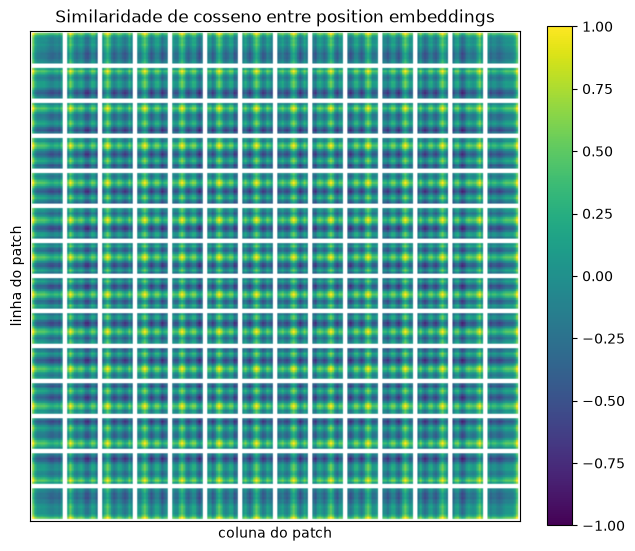

In [5]:
pos = F.normalize(emb.position_embeddings[0, 1:].detach(), dim=1)    # (196, 768), sem o CLS
g = int(math.sqrt(len(pos)))
sim = (pos @ pos.T).view(g, g, g, g).cpu()                           # sim[i, j]: mapa 14x14 do patch (i, j)
tiles = F.pad(sim, (1, 1, 1, 1), value=float("nan"))                 # uma borda branca entre os quadradinhos
mosaic = tiles.permute(0, 2, 1, 3).reshape(g * (g + 2), g * (g + 2))
plt.figure(figsize=(7, 7))
plt.imshow(mosaic, cmap="viridis", vmin=-1, vmax=1)
plt.title("Similaridade de cosseno entre position embeddings")
plt.xlabel("coluna do patch")
plt.ylabel("linha do patch")
plt.xticks([])
plt.yticks([])
plt.colorbar(fraction=0.046)
plt.show()

### TODO 2 — o ViT numa resolução maior

O ViT foi treinado em `224×224`. Para usar uma imagem `384×384` (slide 16), mantemos o patch `16×16`, e a sequência passa a ter $24 \times 24 = 576$ patches. O Transformer aceita qualquer tamanho de sequência, mas a tabela de posições só tem 196 linhas. A saída do artigo: tratar a tabela como uma "imagem" `14×14` com $D$ canais e **interpolá-la em 2D** para `24×24`.

Escrevam `interpolate_pos_embed(pos_embed, new_grid)`: recebe `(1, 1 + g², D)` e devolve `(1, 1 + new_grid², D)`. O primeiro vetor é o do [CLS], que não corresponde a posição nenhuma: ele passa direto.

Dicas:
- `F.interpolate` espera `(B, canais, altura, largura)`: arrumem os $g^2$ vetores em `(1, D, g, g)`;
- usem `mode="bicubic", align_corners=False`, como no artigo.

In [6]:
def interpolate_pos_embed(pos_embed, new_grid):
    cls_pos, patch_pos = pos_embed[:, :1], pos_embed[:, 1:]
    g, D = int(math.sqrt(patch_pos.size(1))), patch_pos.size(2)
    grid = patch_pos.reshape(1, g, g, D).permute(0, 3, 1, 2)            # (1, D, g, g): "imagem" com D canais
    grid = F.interpolate(grid, size=(new_grid, new_grid), mode="bicubic", align_corners=False)
    patch_pos = grid.permute(0, 2, 3, 1).reshape(1, new_grid * new_grid, D)
    return torch.cat([cls_pos, patch_pos], dim=1)

In [7]:
# Teste do TODO 2: compara com a interpolação que o próprio Hugging Face usa
with torch.no_grad():
    P = emb.position_embeddings
    new = interpolate_pos_embed(P, 24)
    ref = emb.interpolate_pos_encoding(torch.zeros(1, 577, 768, device=device), 384, 384)
    same = interpolate_pos_embed(P, 14)
assert new.shape == (1, 577, 768), f"forma errada: {tuple(new.shape)}"
assert torch.equal(new[:, 0], P[:, 0]), "o CLS não deve mudar"
assert torch.allclose(same, P, atol=1e-5), "interpolar para o mesmo tamanho não deveria mudar nada"
assert torch.allclose(new, ref, atol=1e-5), "diferente da interpolação de referência"
print("interpolate_pos_embed ok!")

interpolate_pos_embed ok!


Agora o ViT em `384×384`. Trocamos a tabela de posições do modelo pela interpolada. O `interpolate_pos_encoding=True` só desliga a checagem do tamanho da entrada: como a tabela já tem o tamanho certo, o modelo a usa como está.

In [8]:
original = emb.position_embeddings.data.clone()


def classify_at(img, size, pos_embed):
    emb.position_embeddings.data = pos_embed
    try:
        with torch.no_grad():
            return top5(vit(to_tensor(img, size), interpolate_pos_encoding=True).logits)
    finally:
        emb.position_embeddings.data = original      # devolve a tabela original ao modelo


with torch.no_grad():
    pos384 = interpolate_pos_embed(original, 384 // 16)
for name in ["gato", "cão", "zebra"]:
    print(f"{name:>6} | 224x224: {classify_at(IMG[name], 224, original)}")
    print(f"{'':>6} | 384x384: {classify_at(IMG[name], 384, pos384)}")

  gato | 224x224: tabby (65%), tiger cat (22%), Egyptian cat (4%), carton (1%), computer keyboard (1%)
       | 384x384: tabby (76%), tiger cat (16%), Egyptian cat (3%), computer keyboard (1%), mouse (0%)
   cão | 224x224: Bernese mountain dog (54%), Border collie (33%), collie (8%), Appenzeller (1%), Shetland sheepdog (1%)
       | 384x384: Border collie (71%), collie (27%), Shetland sheepdog (1%), Bernese mountain dog (0%), papillon (0%)
 zebra | 224x224: zebra (100%), gazelle (0%), African elephant (0%), ostrich (0%), tiger (0%)
       | 384x384: zebra (100%), gazelle (0%), ostrich (0%), impala (0%), African elephant (0%)


**Pergunte-se:**
- As previsões em `384×384` mudaram muito? O modelo nunca viu uma sequência de 576 patches no treino. Por que funciona mesmo assim?
- Na figura dos position embeddings, patches da mesma linha e da mesma coluna se parecem. Por que o modelo aprenderia isso sozinho, sem ninguém dizer que a imagem é 2D?
- Rodem `classify_at(IMG["cão"], 224, torch.zeros_like(original))`: o ViT sem nenhuma informação de posição. Ainda acerta? O que isso diz sobre o que a classificação usa?
- E se, em vez de zerar, **embaralharmos** as posições? (`classify_at(IMG["cão"], 224, original[:, torch.cat([torch.tensor([0]), 1 + torch.randperm(196)])])`) Comparem com zerar.

## 2. Swin Transformer

O ViT tem dois problemas para servir de *backbone* (slides 21–23):

- **custo quadrático:** a self-attention compara todos os $N$ tokens com todos, $O(N^2)$. Em imagens grandes, ou com patches pequenos (necessários para segmentar), $N$ explode;
- **uma resolução só:** todas as camadas trabalham no mesmo mapa `14×14`, enquanto detectores e segmentadores querem características em várias escalas, como numa CNN.

O Swin (Liu et al., 2021) resolve os dois: calcula a atenção só **dentro de janelas** $M \times M$ (custo $O(N \cdot M^2)$, linear em $N$), alterna janelas normais com janelas **deslocadas** para a informação passar de uma janela para a outra e, de tempos em tempos, faz **patch merging** (junta 2×2 tokens vizinhos), como um pooling.

Primeiro, a conta dos slides: quantos pares de tokens a atenção compara em cada caso.

In [9]:
def attention_pairs(H, W, patch, window=None):
    N = (H // patch) * (W // patch)
    return N, (N * N if window is None else N * window ** 2)


print(f"{'imagem':>10} | {'ViT: patch 16x16, global':^31} | {'patch 4x4, global':^31} | {'Swin: patch 4x4, janela 7x7':^31}")
for H, W in [(224, 224), (512, 512), (1080, 1920), (2160, 3840)]:
    cols = [attention_pairs(H, W, 16), attention_pairs(H, W, 4), attention_pairs(H, W, 4, window=7)]
    print(f"{f'{H}x{W}':>10} | " + " | ".join(f"{n:>9,} tokens {p:9.1e} pares" for n, p in cols))

    imagem |    ViT: patch 16x16, global     |        patch 4x4, global        |   Swin: patch 4x4, janela 7x7  
   224x224 |       196 tokens   3.8e+04 pares |     3,136 tokens   9.8e+06 pares |     3,136 tokens   1.5e+05 pares
   512x512 |     1,024 tokens   1.0e+06 pares |    16,384 tokens   2.7e+08 pares |    16,384 tokens   8.0e+05 pares
 1080x1920 |     8,040 tokens   6.5e+07 pares |   129,600 tokens   1.7e+10 pares |   129,600 tokens   6.4e+06 pares
 2160x3840 |    32,400 tokens   1.0e+09 pares |   518,400 tokens   2.7e+11 pares |   518,400 tokens   2.5e+07 pares


### TODO 3 — partição em janelas (com e sem shift)

O mapa de tokens chega como `(B, H, W, C)`. Escrevam `window_partition(x, M, shift)`, que devolve `(B · nW, M·M, C)`: cada linha é uma janela $M \times M$, com os tokens em ordem de leitura dentro da janela, e as janelas também em ordem de leitura. A atenção é calculada separadamente em cada linha.

Para o **shift** (SW-MSA), o Swin não cria janelas de tamanhos diferentes: ele **rola** o mapa `shift` posições para cima e para a esquerda e reparte normalmente.

Dicas:
- é igual ao `patchify`: `view(B, H // M, M, W // M, M, C)`, `permute` e `reshape`;
- `torch.roll(x, shifts=(-shift, -shift), dims=(1, 2))`.

In [10]:
def window_partition(x, M, shift=0):
    if shift:
        x = torch.roll(x, shifts=(-shift, -shift), dims=(1, 2))         # desloca a grade de janelas
    B, H, W, C = x.shape
    x = x.view(B, H // M, M, W // M, M, C).permute(0, 1, 3, 2, 4, 5)    # (B, jan_linha, jan_coluna, i, j, C)
    return x.reshape(-1, M * M, C)

In [11]:
# Teste do TODO 3: compara com uma versão em loop
def window_partition_loop(x, M, shift=0):
    B, H, W, C = x.shape
    out = []
    for b in range(B):
        for r in range(0, H, M):
            for c in range(0, W, M):
                rows = [(r + i + shift) % H for i in range(M)]
                cols = [(c + j + shift) % W for j in range(M)]
                out.append(x[b][rows][:, cols].reshape(M * M, C))
    return torch.stack(out)


x = torch.randn(2, 8, 12, 3)
for shift in [0, 2]:
    w = window_partition(x, 4, shift)
    assert w.shape == (2 * 2 * 3, 16, 3), f"forma errada: {tuple(w.shape)}"
    assert torch.equal(w, window_partition_loop(x, 4, shift)), f"janelas erradas (shift = {shift})"
print("window_partition ok!")

window_partition ok!


### 2.1 Vendo as janelas

Num mapa `8×8` com janelas `4×4` (a figura do artigo), pintamos cada token com o número da janela em que ele caiu. Para isso passamos pela `window_partition` de vocês um mapa em que cada token carrega a própria posição.

Com o shift, a janela do canto junta pedaços de lados opostos da imagem (efeito do `roll`). O Swin usa uma **máscara de atenção** para que esses pedaços não conversem entre si; na prática, as janelas deslocadas são as 9 regiões do terceiro painel.

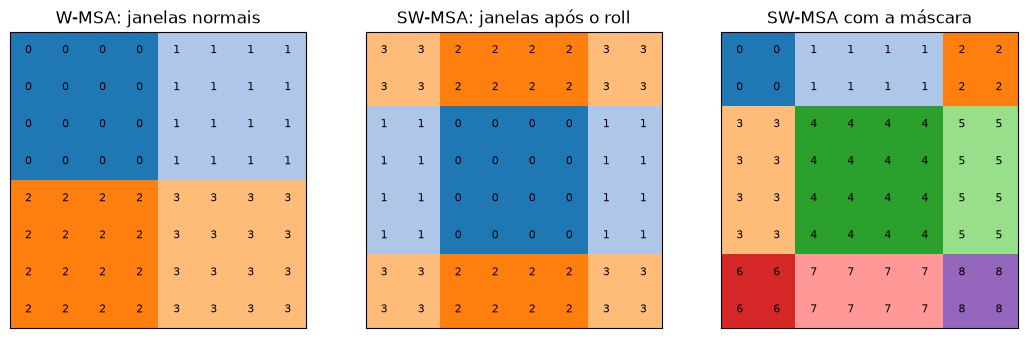

In [12]:
def window_ids(H, W, M, shift):
    """Para cada token (i, j), o índice da janela em que ele cai."""
    pos = torch.arange(H * W, dtype=torch.float32).view(1, H, W, 1)     # cada token guarda a própria posição
    wins = window_partition(pos, M, shift)[..., 0].long()               # (nW, M*M): as posições em cada janela
    ids = torch.empty(H * W, dtype=torch.long)
    for k, w in enumerate(wins):
        ids[w] = k
    return ids.view(H, W)


def effective_ids(H, W, M, shift):
    """As janelas que a atenção realmente usa, já com a máscara: as fronteiras ficam em shift, shift + M, ..."""
    r = torch.div(torch.arange(H) - shift, M, rounding_mode="floor") + 1
    c = torch.div(torch.arange(W) - shift, M, rounding_mode="floor") + 1
    return r[:, None] * (W // M + 1) + c[None, :]


def draw_ids(ax, ids, title):
    ax.imshow(ids, cmap="tab20", vmin=0, vmax=19)
    for (i, j), v in np.ndenumerate(ids.numpy()):
        ax.text(j, i, v, ha="center", va="center", fontsize=8)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
draw_ids(axes[0], window_ids(8, 8, 4, 0), "W-MSA: janelas normais")
draw_ids(axes[1], window_ids(8, 8, 4, 2), "SW-MSA: janelas após o roll")
draw_ids(axes[2], effective_ids(8, 8, 4, 2), "SW-MSA com a máscara")
plt.show()

Alternando blocos com e sem shift, a informação se espalha (slide 34). Abaixo, num mapa `16×16` com janelas `4×4`, os tokens que já podem ter influenciado o token marcado depois de 1, 2, 3, ... blocos.

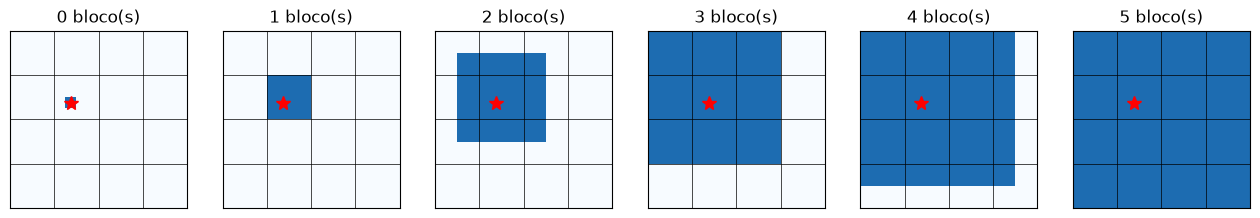

In [13]:
def reach_after(n_blocks, H=16, W=16, M=4, start=(6, 5)):
    reach = torch.zeros(H, W, dtype=torch.bool)
    reach[start] = True
    for b in range(n_blocks):
        ids = effective_ids(H, W, M, shift=0 if b % 2 == 0 else M // 2)   # W-MSA e SW-MSA alternados
        reach = torch.isin(ids, ids[reach])          # todos os tokens de alguma janela já alcançada
    return reach


fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for b, ax in enumerate(axes):
    ax.imshow(reach_after(b), cmap="Blues", vmin=0, vmax=1.3)
    ax.plot(5, 6, "r*", ms=10)
    ax.set_title(f"{b} bloco(s)")
    ax.set_xticks(np.arange(-0.5, 16, 4))
    ax.set_yticks(np.arange(-0.5, 16, 4))
    ax.grid(color="k", lw=0.5)
    ax.tick_params(labelbottom=False, labelleft=False, length=0)
plt.show()

### 2.2 Patch merging e o mapa hierárquico

O patch merging (slide 30) é "só uma rede simples": concatena cada bloco 2×2 de tokens vizinhos ($C \to 4C$) e projeta para $2C$. A resolução cai pela metade e o número de canais dobra, como numa CNN. Conferimos a nossa versão com a camada do Swin-T pré-treinado e olhamos o mapa de características de cada estágio.

patch merging igual ao do Swin-T: True
Swin: [(96, 56, 56), (192, 28, 28), (384, 14, 14), (768, 7, 7), (768, 7, 7)]
ViT:  [(197, 768), (197, 768), (197, 768)] ... (13 vezes a mesma forma)


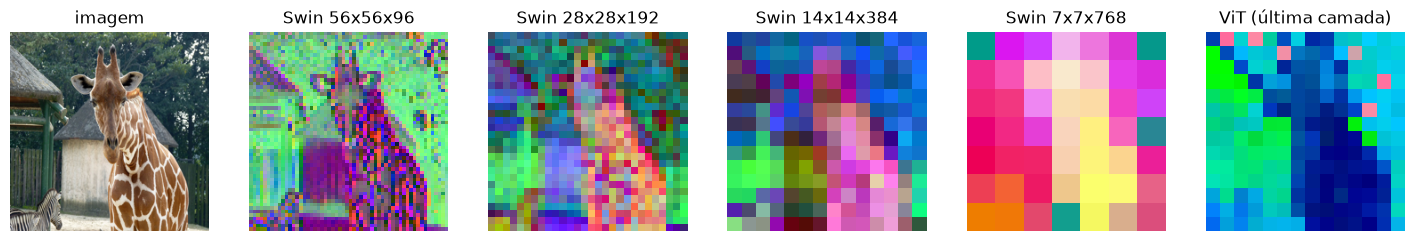

In [14]:
from transformers import SwinModel

swin = SwinModel.from_pretrained("microsoft/swin-tiny-patch4-window7-224").to(device).eval()


def patch_merging(x, norm, reduction):
    """(B, H, W, C) -> (B, H/2, W/2, 2C)."""
    x0, x1 = x[:, 0::2, 0::2], x[:, 1::2, 0::2]      # (linha par, coluna par), (ímpar, par)
    x2, x3 = x[:, 0::2, 1::2], x[:, 1::2, 1::2]      # (par, ímpar), (ímpar, ímpar)
    return reduction(norm(torch.cat([x0, x1, x2, x3], dim=-1)))


# a camada de patch merging depois do 1º estágio do Swin-T
merge = next(m for m in swin.modules() if type(m).__name__ == "SwinPatchMerging")
x = torch.randn(1, 56, 56, 96, device=device)
with torch.no_grad():
    ours = patch_merging(x, merge.norm, merge.reduction)
    ref = merge(x.view(1, 56 * 56, 96), (56, 56)).view(1, 28, 28, 192)
print("patch merging igual ao do Swin-T:", torch.allclose(ours, ref, atol=1e-4))

x = to_tensor(IMG["girafa"])
with torch.no_grad():
    swin_maps = swin(x, output_hidden_states=True).reshaped_hidden_states    # (1, C, H, W) por estágio
    vit_maps = vit.vit(x, output_hidden_states=True).hidden_states           # (1, 1 + 196, 768) por camada
print("Swin:", [tuple(h.shape[1:]) for h in swin_maps])
print("ViT: ", [tuple(h.shape[1:]) for h in vit_maps][:3], f"... ({len(vit_maps)} vezes a mesma forma)")

maps = [h[0].permute(1, 2, 0) for h in swin_maps[:4]] + [vit_maps[-1][0, 1:].view(14, 14, -1)]
show([IMG["girafa"].resize((224, 224))] + [pca_rgb([m])[0] for m in maps],
     ["imagem"] + [f"Swin {m.shape[0]}x{m.shape[1]}x{m.shape[2]}" for m in maps[:4]] + ["ViT (última camada)"], size=3)

**Pergunte-se:**
- No painel "após o roll", uma janela junta pedaços de cantos opostos da imagem. O que aconteceria sem a máscara de atenção?
- Por que rolar o mapa em vez de usar janelas de tamanhos diferentes nas bordas? (Contem quantas janelas existem e de que tamanho: com o roll, todas são $M \times M$ e cabem num único batch.)
- Quantos blocos são necessários para o token marcado "ver" o mapa `16×16` inteiro? E se não houvesse o shift?
- Na tabela, para uma imagem 4K com patches 4×4, quantas vezes a atenção global custa mais que a do Swin? Por que é exatamente $N / M^2$?
- Nos mapas da PCA, o que muda do 1º para o último estágio do Swin? Qual deles vocês usariam para segmentar? E para classificar?

## 3. Masked Autoencoders (MAE)

O MAE (He et al., 2022) é o "BERT da visão": esconde partes da entrada e treina a rede para reconstruí-las. Os slides destacam as diferenças para o BERT:

- **mask ratio alto:** o BERT esconde 15% das palavras; o MAE esconde **75%** dos patches. Imagens são redundantes: com pouca coisa escondida, dá para "interpolar" o que falta olhando os vizinhos, sem entender nada da imagem;
- **encoder-decoder assimétrico:** o encoder (grande) recebe **só os patches visíveis**, sem tokens de máscara. Um decoder pequeno recebe tudo (visíveis + `[MASK]`) e reconstrói os pixels. Com 75% de máscara, o encoder processa 4× menos tokens.

Quem decide quais patches o encoder vê é o **random masking**.

### TODO 4 — random masking

Escrevam `random_masking(x, mask_ratio, noise)`, que recebe os patch embeddings `x` `(B, N, D)` e devolve:
- `x_visible` `(B, N_keep, D)`, com $N_{keep} = \lfloor N (1 - \text{mask ratio}) \rfloor$ patches **sorteados, diferentes para cada imagem**;
- `mask` `(B, N)`, com **1 nos patches escondidos** e 0 nos visíveis, na ordem original dos patches;
- `ids_restore` `(B, N)`, a permutação que desfaz o embaralhamento: o decoder a usa para recolocar cada token na posição certa.

O truque do artigo: sortear um ruído por patch e ordenar. `ids_shuffle = noise.argsort(dim=1)` é uma permutação aleatória, e os $N_{keep}$ primeiros índices são os que ficam. A permutação inversa de uma permutação `s` é `s.argsort()`.

Dicas:
- para pegar as linhas `ids_keep` de cada imagem: `torch.gather(x, 1, ids_keep.unsqueeze(-1).expand(-1, -1, D))`;
- a máscara: comecem com `N_keep` zeros seguidos de `N - N_keep` uns (na ordem embaralhada) e desembaralhem com `torch.gather(..., 1, ids_restore)`.

In [15]:
def random_masking(x, mask_ratio, noise=None):
    B, N, D = x.shape
    n_keep = int(N * (1 - mask_ratio))
    if noise is None:
        noise = torch.rand(B, N, device=x.device)
    ids_shuffle = noise.argsort(dim=1)               # permutação aleatória, uma por imagem
    ids_restore = ids_shuffle.argsort(dim=1)         # a permutação inversa
    ids_keep = ids_shuffle[:, :n_keep]
    x_visible = torch.gather(x, 1, ids_keep.unsqueeze(-1).expand(-1, -1, D))
    mask = torch.ones(B, N, device=x.device)
    mask[:, :n_keep] = 0                             # 0 = visível, 1 = escondido (na ordem embaralhada)
    mask = torch.gather(mask, 1, ids_restore)        # de volta à ordem original dos patches
    return x_visible, mask, ids_restore

In [16]:
# Teste do TODO 4
torch.manual_seed(0)
x = torch.randn(3, 10, 4)
xv, mask, ids_restore = random_masking(x, 0.7)
assert xv.shape == (3, 3, 4) and mask.shape == (3, 10) and ids_restore.shape == (3, 10), "formas erradas"
assert (mask.sum(1) == 7).all(), "cada imagem deve ter exatamente 7 dos 10 patches escondidos"
for b in range(3):
    kept = x[b][mask[b] == 0]                        # os visíveis, na ordem original
    assert torch.equal(xv[b][xv[b][:, 0].argsort()], kept[kept[:, 0].argsort()]), \
        "x_visible deve ter exatamente os patches com mask = 0"
assert not torch.equal(mask[0], mask[1]), "cada imagem deve ter a sua própria máscara"
# o que o decoder faz: completa com tokens de máscara (aqui, zeros) e desembaralha com ids_restore
full = torch.cat([xv, torch.zeros(3, 7, 4)], dim=1)
full = torch.gather(full, 1, ids_restore.unsqueeze(-1).expand(-1, -1, 4))
assert torch.equal(full[mask == 0], x[mask == 0]), "ids_restore não devolve os visíveis às posições originais"
noise = torch.rand(3, 10)
assert torch.equal(random_masking(x, 0.7, noise)[1], random_masking(x, 0.7, noise)[1]), \
    "o mesmo ruído deve dar a mesma máscara"
print("random_masking ok!")

random_masking ok!


### 3.1 Plugando no MAE pré-treinado

O MAE do Hugging Face chama um método `random_masking(sequence, noise)` dentro do embedding. Trocamos esse método pela função de vocês: daqui em diante, quem decide o que o encoder vê é o código de vocês.

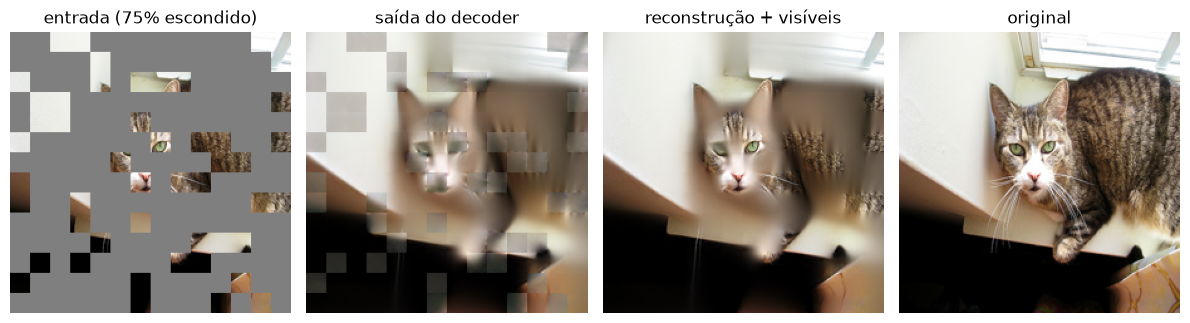

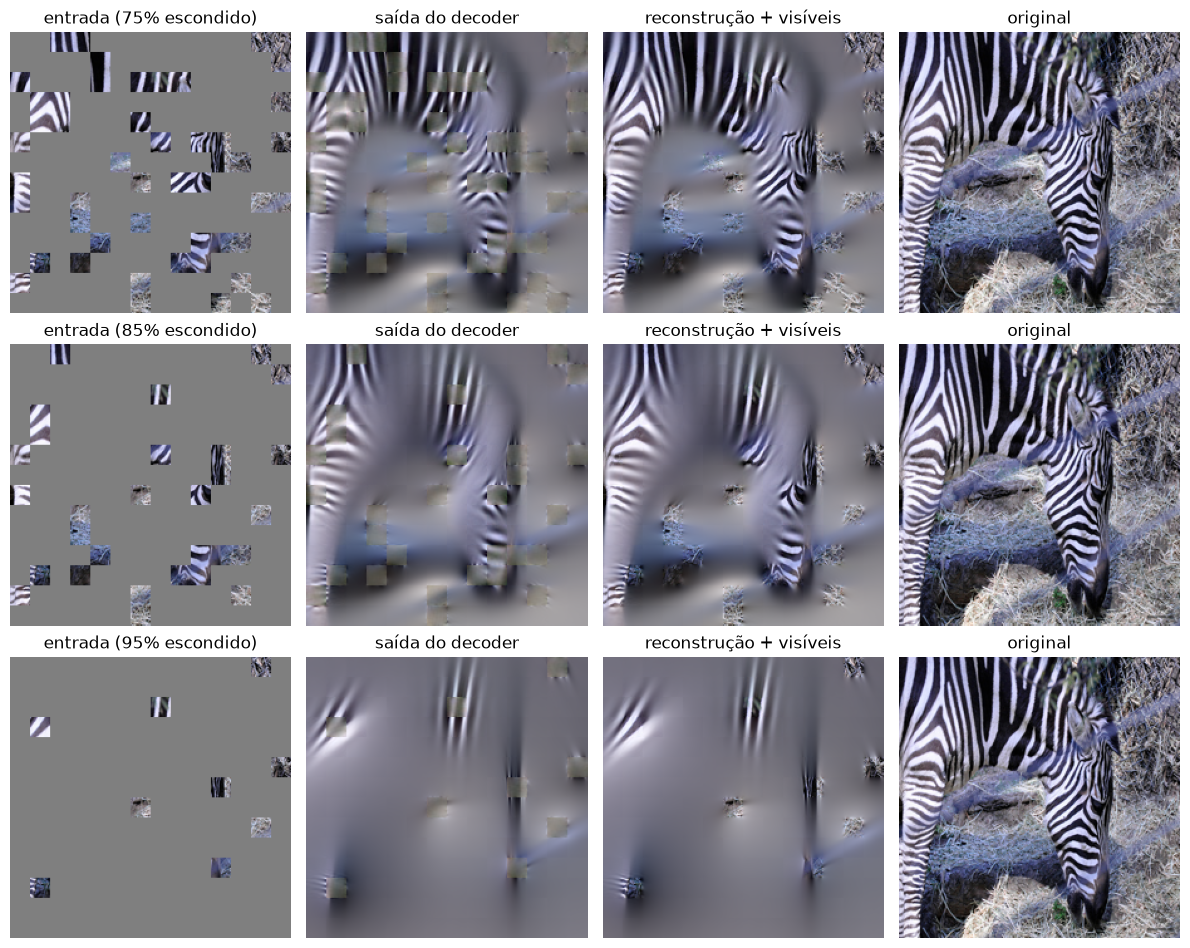

In [17]:
from transformers import ViTMAEForPreTraining

mae = ViTMAEForPreTraining.from_pretrained("facebook/vit-mae-base", attn_implementation="eager").to(device).eval()


def set_mask_ratio(ratio):
    mae.vit.embeddings.random_masking = lambda seq, noise=None: random_masking(seq, ratio, noise)


@torch.no_grad()
def mae_reconstruct(img, ratio, seed=0):
    set_mask_ratio(ratio)
    x = to_tensor(img)
    noise = torch.rand(1, 196, generator=torch.Generator().manual_seed(seed)).to(device)
    out = mae(pixel_values=x, noise=noise)
    m = out.mask[0].view(14, 14).repeat_interleave(16, 0).repeat_interleave(16, 1).cpu().numpy()[..., None]
    orig, rec = to_image(x[0]), to_image(mae.unpatchify(out.logits)[0])
    return [orig * (1 - m) + 0.5 * m, rec, orig * (1 - m) + rec * m, orig]


def show_mae(img, ratios=(0.75,), seed=0):
    fig, axes = plt.subplots(len(ratios), 4, figsize=(12, 3.2 * len(ratios)), squeeze=False)
    for r, ratio in enumerate(ratios):
        titles = [f"entrada ({ratio:.0%} escondido)", "saída do decoder", "reconstrução + visíveis", "original"]
        for ax, im, t in zip(axes[r], mae_reconstruct(img, ratio, seed), titles):
            ax.imshow(im)
            ax.set_title(t)
            ax.axis("off")
    plt.tight_layout()
    plt.show()


show_mae(IMG["gato"])
show_mae(IMG["zebra"], ratios=(0.75, 0.85, 0.95))

E a eficiência: o encoder com 75% de máscara processa só 49 dos 196 patches (+ o [CLS]).

In [18]:
x = to_tensor(IMG["gato"]).repeat(64, 1, 1, 1)
for ratio in [0.0, 0.75]:
    set_mask_ratio(ratio)
    with torch.no_grad():
        mae.vit(x)                                   # aquecimento
        sync()
        t = time.time()
        for _ in range(5):
            mae.vit(x)
        sync()
    print(f"mask ratio {ratio:.0%}: o encoder vê {int(196 * (1 - ratio)) + 1:3d} tokens, "
          f"{(time.time() - t) / 5 * 1000:6.1f} ms por batch de 64 imagens")

mask ratio 0%: o encoder vê 197 tokens,  305.4 ms por batch de 64 imagens


mask ratio 75%: o encoder vê  50 tokens,   73.5 ms por batch de 64 imagens


**Pergunte-se:**
- Com 95% escondido sobram 9 patches. O que o MAE ainda acerta? O que ele erra? Por que a reconstrução sai borrada?
- A "saída do decoder" é ruim justamente nos patches **visíveis**. Por quê? (Dica: em quais patches a loss do MAE é calculada?)
- Por que 15% de máscara, que funciona para o BERT, seria uma tarefa fácil demais para imagens?
- Quantas vezes o encoder com 75% de máscara foi mais rápido? Mais ou menos que 4×? Por quê?
- Rodem `show_mae` nas outras imagens de `IMG`, ou numa imagem de vocês (`Image.open(...)`).

## 4. Que representação cada pré-treino produz?

Nos slides aparecem duas famílias de pré-treino auto-supervisionado:
- **reconstrução** (MAE): prever os pixels escondidos;
- **comparação de visões** (DINO, MSN): duas visões da mesma imagem devem ter a mesma representação. O **MSN** (Assran et al., 2022) junta as duas ideias: a visão *âncora* é mascarada, a visão *alvo* não, e as duas são comparadas por meio de **protótipos** aprendidos, como no SwAV.

Comparamos 4 ViT-B/16, com a mesma arquitetura, que só diferem no pré-treino: supervisionado (o da Parte 1), MAE (o da Parte 3), DINO e MSN. Todos congelados: a representação é o token [CLS] da última camada.

**Protocolo:** CIFAR-10 (redimensionado para 224) com só **1, 5 ou 25 imagens rotuladas por classe**. O classificador é o mais simples possível: o **protótipo** de cada classe é a média das representações das suas imagens rotuladas, e cada imagem de teste vai para a classe do protótipo mais parecido (cosseno). Nenhum peso é treinado. Cada número é a média de 5 sorteios das imagens rotuladas.

In [19]:
import pandas as pd
from huggingface_hub import hf_hub_download
from transformers import ViTModel, ViTMSNModel

dino = ViTModel.from_pretrained("facebook/dino-vitb16", add_pooling_layer=False,
                                attn_implementation="eager").to(device).eval()
msn = ViTMSNModel.from_pretrained("facebook/vit-msn-base", attn_implementation="eager").to(device).eval()
set_mask_ratio(0.0)                                  # o MAE agora vê a imagem inteira


def mae_encoder(x, **kw):
    # ruído crescente: o "embaralhamento" vira a identidade e os patches ficam na ordem original
    noise = torch.arange(196, device=x.device).float().expand(x.size(0), -1)
    return mae.vit(x, noise=noise, **kw)


encoders = {"supervisionado": vit.vit, "MAE": mae_encoder, "DINO": dino, "MSN": msn}

# Só precisamos de 2.250 imagens: usamos o conjunto de teste do CIFAR-10 (10 mil imagens), um arquivo
# de ~25 MB no Hugging Face Hub, e tiramos dele as imagens "rotuladas" e as de teste, sem sobreposição
path = hf_hub_download("uoft-cs/cifar10", "plain_text/test-00000-of-00001.parquet", repo_type="dataset")
df = pd.read_parquet(path)
cifar_x = np.stack([np.array(Image.open(io.BytesIO(im["bytes"])).convert("RGB")) for im in df["img"]])
cifar_y = df["label"].to_numpy()                     # (10000,), cifar_x: (10000, 32, 32, 3)

rng = np.random.default_rng(0)
by_class = [rng.permutation(np.flatnonzero(cifar_y == c)) for c in range(10)]
pool_idx = np.concatenate([i[:25] for i in by_class])       # de onde sorteamos os poucos rótulos
test_idx = np.concatenate([i[25:225] for i in by_class])    # 2.000 imagens de teste
y_pool = torch.tensor(cifar_y[pool_idx]).to(device)
y_test = torch.tensor(cifar_y[test_idx]).to(device)


def cifar_batch(idx):
    x = torch.tensor(cifar_x[idx]).permute(0, 3, 1, 2).float() / 255      # (B, 3, 32, 32)
    x = F.interpolate(x, size=224, mode="bicubic", align_corners=False).clamp(0, 1)
    return ((x - MEAN) / STD).to(device)


@torch.no_grad()
def cifar_features(encoder, idx, pool="cls", bs=100):
    feats = []
    for i in range(0, len(idx), bs):
        with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
            h = encoder(cifar_batch(idx[i:i + bs])).last_hidden_state
        feats.append(h[:, 0] if pool == "cls" else h[:, 1:].mean(1))     # [CLS] ou média dos patches
    return F.normalize(torch.cat(feats).float(), dim=1)


def prototype_accuracy(f_pool, f_test, n_shot, seeds=5):
    accs = []
    for s in range(seeds):
        g = torch.Generator().manual_seed(s)
        protos = []
        for c in range(10):
            idx = torch.nonzero(y_pool == c).flatten().cpu()
            idx = idx[torch.randperm(len(idx), generator=g)[:n_shot]]
            protos.append(f_pool[idx.to(device)].mean(0))                 # protótipo da classe c
        protos = F.normalize(torch.stack(protos), dim=1)
        accs.append(((f_test @ protos.T).argmax(1) == y_test).float().mean().item())
    return np.mean(accs)


feats = {}
for name, enc in encoders.items():
    t = time.time()
    feats[name] = (cifar_features(enc, pool_idx), cifar_features(enc, test_idx))
    print(f"características do {name}: {time.time() - t:.0f} s")

shots = [1, 5, 25]
print(f"\n{'pré-treino':<16}" + "".join(f"{f'{n} rótulo(s)/classe':>21}" for n in shots))
for name, (fp, ft) in feats.items():
    print(f"{name:<16}" + "".join(f"{prototype_accuracy(fp, ft, n):>21.3f}" for n in shots))

características do supervisionado: 6 s


características do MAE: 5 s


características do DINO: 5 s


características do MSN: 5 s

pré-treino         1 rótulo(s)/classe   5 rótulo(s)/classe  25 rótulo(s)/classe


supervisionado                  0.686                0.834                0.883
MAE                             0.312                0.466                0.565
DINO                            0.651                0.848                0.903
MSN                             0.576                0.824                0.872


### 4.1 Para onde o [CLS] olha

Na última camada, quanto o token [CLS] presta atenção em cada patch (média das 12 cabeças). É a figura famosa do DINO: sem nunca ver um rótulo ou uma máscara, a atenção separa o objeto do fundo.

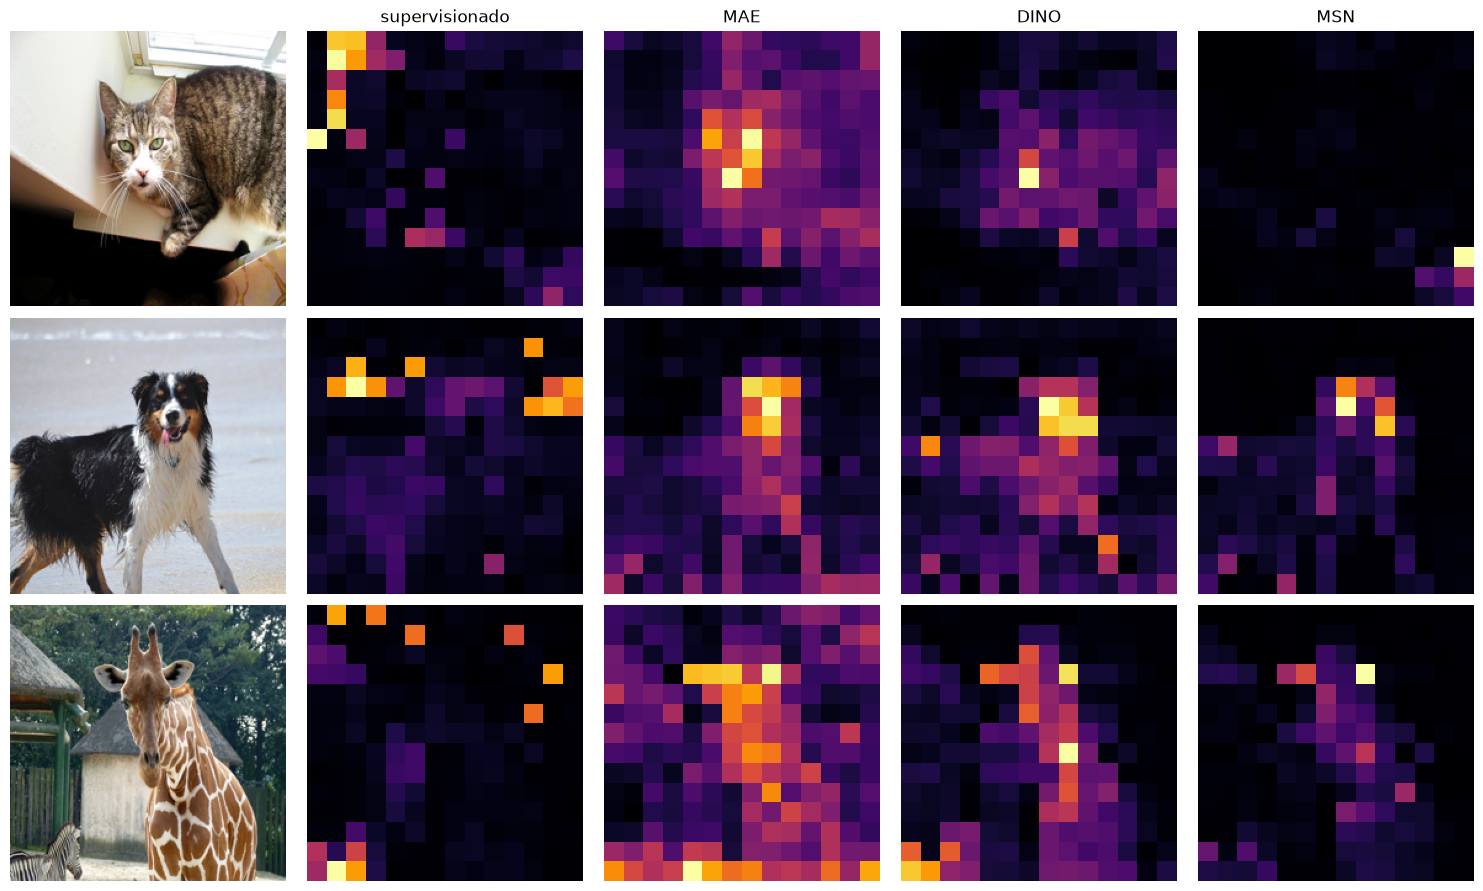

In [20]:
@torch.no_grad()
def cls_attention(encoder, img):
    att = encoder(to_tensor(img), output_attentions=True).attentions[-1]     # (1, cabeças, 197, 197)
    a = att[0, :, 0, 1:].mean(0).view(14, 14)                                # [CLS] -> patches, média das cabeças
    return (a / a.max()).cpu().numpy()


names = ["gato", "cão", "girafa"]
fig, axes = plt.subplots(len(names), 1 + len(encoders), figsize=(3 * (1 + len(encoders)), 3 * len(names)))
for r, n in enumerate(names):
    axes[r, 0].imshow(IMG[n].resize((224, 224)))
    for c, (name, enc) in enumerate(encoders.items(), 1):
        axes[r, c].imshow(cls_attention(enc, IMG[n]), cmap="inferno")
        axes[0, c].set_title(name)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Pergunte-se:**
- Com 1 rótulo por classe, qual pré-treino ganha? E com 25? A ordem muda?
- O MAE reconstrói imagens muito bem (Parte 3), mas a representação congelada dele é a pior aqui. Por quê? O que a reconstrução obriga o modelo a guardar que não ajuda a separar classes? (Nos artigos, o MAE só brilha depois de *fine-tuning*.)
- O MSN foi pensado para o regime de poucos rótulos (*label-efficient*). Os números confirmam?
- O supervisionado viu 14 milhões de imagens **rotuladas** no ImageNet-21k. A comparação é justa? Até onde os auto-supervisionados chegam sem nenhum desses rótulos?
- O [CLS] do MAE nunca foi treinado para resumir a imagem: a loss é só nos pixels. Troquem para a média dos patches no MAE (`cifar_features(mae_encoder, ..., pool="mean")`). Melhora?
- Nos mapas de atenção, qual modelo "encontra" o objeto? Isso combina com a tabela?

## 5. Segment Anything (SAM)

O SAM (Kirillov et al., 2023) é um foundation model para **segmentação por prompt**: dado um prompt (pontos, caixa ou máscara), devolve uma máscara válida. Os slides destacam três decisões:

- **arquitetura dividida:** um encoder pesado (um ViT pré-treinado com MAE!) roda **uma vez** por imagem; um decoder leve roda em milissegundos **para cada prompt**. É isso que permite o uso interativo;
- **ambiguidade:** um ponto pode querer dizer o todo, uma parte ou uma subparte. Por isso o SAM devolve **3 máscaras**, cada uma com uma estimativa da própria qualidade (o IoU previsto);
- **dados:** o SA-1B, com 11 milhões de imagens e 1,1 bilhão de máscaras, anotadas com o próprio modelo no loop.

Usamos o SAM ViT-B, o menor.

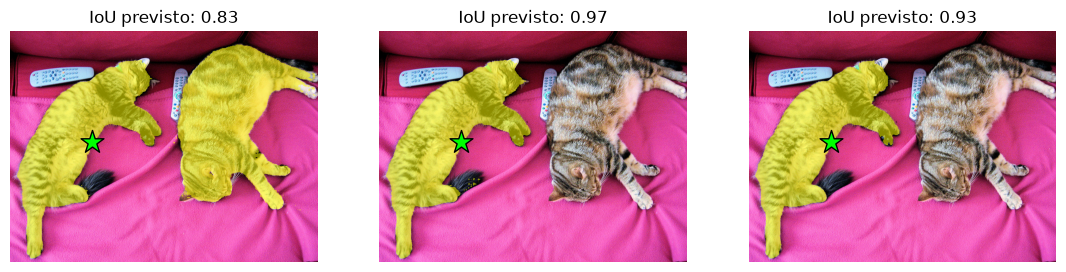

In [21]:
from transformers import SamModel, SamProcessor

sam = SamModel.from_pretrained("facebook/sam-vit-base").to(device).eval()
sam_proc = SamProcessor.from_pretrained("facebook/sam-vit-base")


@torch.no_grad()
def sam_embed(img):
    """A parte cara: roda o encoder uma vez e guarda o resultado junto com os tamanhos da imagem."""
    inputs = sam_proc(img, return_tensors="pt")
    return {"img": img, "emb": sam.get_image_embeddings(inputs["pixel_values"].to(device)),
            "sizes": (inputs["original_sizes"], inputs["reshaped_input_sizes"])}


@torch.no_grad()
def sam_predict(E, points=None, labels=None, box=None, multimask=True):
    """A parte barata: prompt -> máscaras (K, H, W) booleanas e o IoU previsto de cada uma.
    points: lista de (x, y) em pixels; labels: 1 = objeto, 0 = fundo; box: (x0, y0, x1, y1)."""
    (H, W), (h, w) = E["sizes"][0][0].tolist(), E["sizes"][1][0].tolist()
    scale = torch.tensor([w / W, h / H], device=device)            # pixels da imagem -> entrada 1024 do SAM
    prompts = {}
    if points is not None:
        prompts["input_points"] = torch.tensor(np.asarray(points, dtype=np.float32), device=device).view(1, 1, -1, 2) * scale
        labels = [1] * len(points) if labels is None else labels
        prompts["input_labels"] = torch.tensor(labels, device=device).view(1, 1, -1)
    if box is not None:
        prompts["input_boxes"] = torch.tensor(box, dtype=torch.float32, device=device).view(1, 1, 4) * scale.repeat(2)
    out = sam(image_embeddings=E["emb"], multimask_output=multimask, **prompts)
    masks = sam_proc.image_processor.post_process_masks(out.pred_masks.cpu(), *E["sizes"])[0][0]
    return masks.numpy(), out.iou_scores[0, 0].cpu().numpy()


def show_masks(E, masks, scores, points=None, labels=None, box=None):
    fig, axes = plt.subplots(1, len(masks), figsize=(4.5 * len(masks), 3.6), squeeze=False)
    for ax, m, s in zip(axes[0], masks, scores):
        ax.imshow(E["img"])
        ax.imshow(np.ma.masked_where(~m, m), alpha=0.55, cmap="autumn", vmin=0, vmax=1)
        if points is not None:
            pts = np.array(points)
            lab = np.array([1] * len(points) if labels is None else labels)
            ax.scatter(*pts[lab == 1].T, c="lime", marker="*", s=300, edgecolor="k")
            ax.scatter(*pts[lab == 0].T, c="red", marker="X", s=200, edgecolor="k")
        if box is not None:
            x0, y0, x1, y1 = box
            ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=2))
        ax.set_title(f"IoU previsto: {s:.2f}")
        ax.axis("off")
    plt.show()


E_cats = sam_embed(IMG["dois gatos"])
pt = [(170, 230)]
masks, scores = sam_predict(E_cats, points=pt)          # um ponto -> 3 máscaras (ambiguidade)
show_masks(E_cats, masks, scores, points=pt)

Outros prompts na mesma imagem: o encoder não roda de novo, só o decoder.

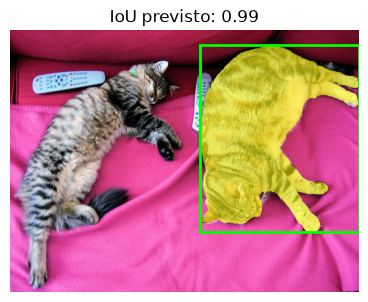

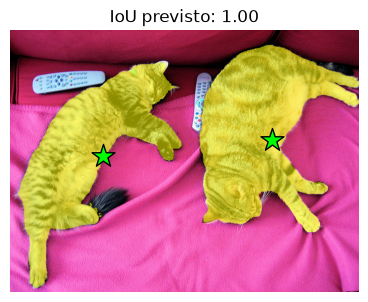

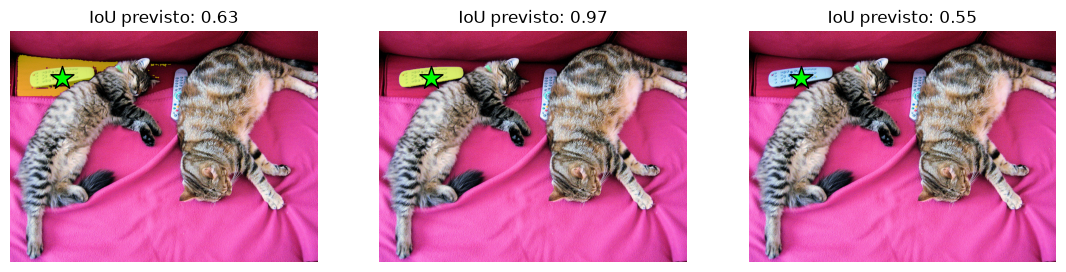

encoder (uma vez por imagem):  197.9 ms
decoder (uma vez por prompt):   15.3 ms


In [22]:
box = (348, 26, 640, 370)
show_masks(E_cats, *sam_predict(E_cats, box=box, multimask=False), box=box)

pts, labels = [(170, 230), (480, 200)], [1, 1]
show_masks(E_cats, *sam_predict(E_cats, points=pts, labels=labels, multimask=False), points=pts, labels=labels)

pts = [(108, 96)]                                        # o controle remoto
show_masks(E_cats, *sam_predict(E_cats, points=pts), points=pts)


def bench(fn, n=10):
    fn()
    sync()
    t = time.time()
    for _ in range(n):
        fn()
    sync()
    return (time.time() - t) / n * 1000


print(f"encoder (uma vez por imagem): {bench(lambda: sam_embed(IMG['dois gatos']), 3):6.1f} ms")
print(f"decoder (uma vez por prompt): {bench(lambda: sam_predict(E_cats, points=[(170, 230)])):6.1f} ms")

**Pergunte-se:**
- No primeiro ponto, a que correspondem as 3 máscaras? A de maior IoU previsto é sempre a que vocês queriam?
- Mudem as coordenadas: cliquem na cabeça de um gato, no sofá, no outro controle remoto. Quando a ambiguidade aparece mais?
- Com um ponto positivo em cada gato, o SAM devolve os dois juntos. Acrescentem um ponto **negativo** (`labels = [1, 1, 0]`) num dos gatos: o que acontece?
- Quanto custou o encoder em relação ao decoder? Numa ferramenta de anotação em que a pessoa clica 20 vezes na mesma imagem, quanto isso economiza?

## 6. Matcher: segmentação one-shot sem treino

O SAM segmenta qualquer coisa, mas precisa que alguém diga **onde**. O Matcher (Liu et al., 2024) tira a pessoa do loop: dada **uma** imagem de referência com a máscara de um objeto, ele encontra e segmenta o mesmo tipo de objeto em outras imagens, **sem treinar nada** (slides 101–106):

1. extrai características dos patches das duas imagens com um encoder auto-supervisionado (DINOv2);
2. **casa** os patches do objeto na referência com patches da imagem alvo;
3. agrupa os pontos casados com k-means;
4. usa os grupos como prompts do SAM e gera várias máscaras candidatas;
5. filtra as candidatas e junta as boas.

Vamos montar uma versão simplificada. A referência é o cão do setup, segmentado pelo SAM com uma caixa.

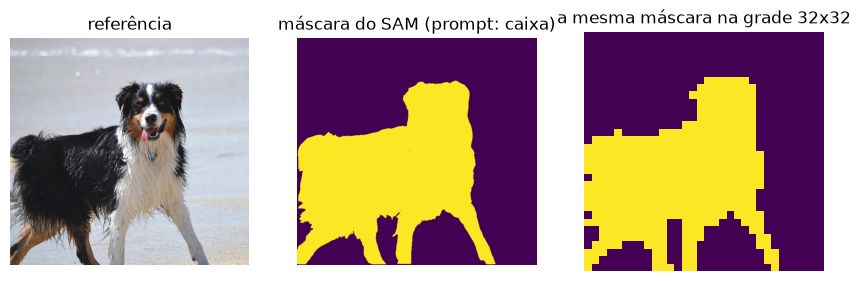

In [23]:
from transformers import Dinov2Model

dinov2 = Dinov2Model.from_pretrained("facebook/dinov2-base").to(device).eval()
G = 32                                               # imagem 448x448 com patches 14x14 -> grade 32x32


@torch.no_grad()
def patch_features(img):
    h = dinov2(pixel_values=to_tensor(img, G * 14)).last_hidden_state[0, 1:]   # (G*G, D), sem o [CLS]
    return F.normalize(h, dim=1)


def mask_to_grid(mask):
    """Máscara (H, W) -> (G*G,) booleana: o patch é do objeto se mais da metade dele estiver na máscara."""
    m = torch.tensor(mask, dtype=torch.float32)[None, None]
    return (F.interpolate(m, size=(G, G), mode="area")[0, 0] > 0.5).flatten().to(device)


ref_img = IMG["cão"]
ref_mask = sam_predict(sam_embed(ref_img), box=(5, 110, 545, 606), multimask=False)[0][0]
f_ref, m_ref = patch_features(ref_img), mask_to_grid(ref_mask)
show([ref_img, ref_mask, m_ref.view(G, G).float().cpu()],
     ["referência", "máscara do SAM (prompt: caixa)", f"a mesma máscara na grade {G}x{G}"])

Antes de casar, vale ver o que essas características capturam. Abaixo, uma PCA conjunta (3 componentes → RGB) dos patches de quatro imagens de cães: cores parecidas = características parecidas.

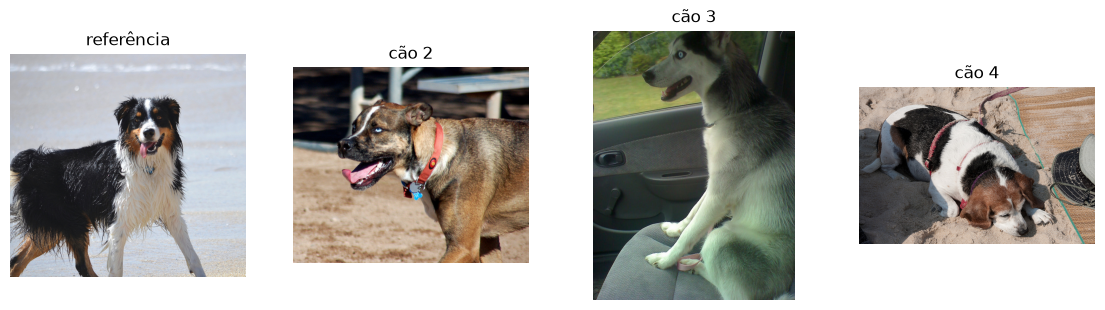

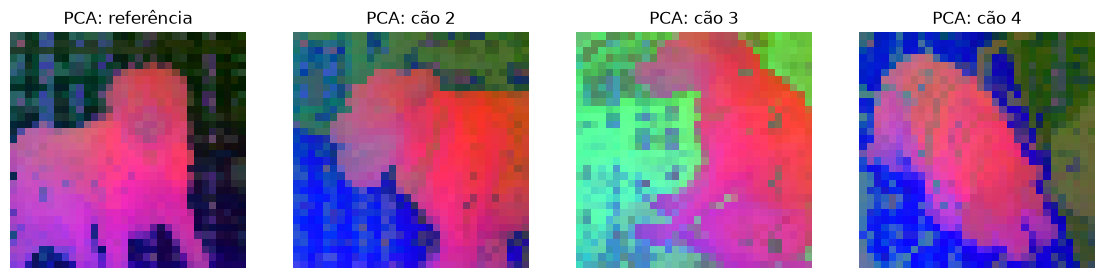

In [24]:
targets = {name: load_image(i) for name, i in {"cão 2": 364636, "cão 3": 131273, "cão 4": 511398}.items()}
rgbs = pca_rgb([f_ref.view(G, G, -1)] + [patch_features(im).view(G, G, -1) for im in targets.values()])
show([ref_img] + list(targets.values()), ["referência"] + list(targets))
show(rgbs, ["PCA: referência"] + [f"PCA: {n}" for n in targets])

### TODO 5 — casamento bidirecional de patches

Para cada patch do objeto na referência, o patch mais parecido do alvo (cosseno) é um candidato. Mas só o caminho "de ida" erra muito: todo patch tem *algum* vizinho mais próximo, mesmo que o objeto nem esteja no alvo. O Matcher faz também o caminho **de volta**: a partir do patch encontrado no alvo, procura o mais parecido em **toda** a referência. Se a volta cai **dentro** do objeto, o casamento é aceito; se cai no fundo, é descartado.

Escrevam `match_patches(f_ref, mask_ref, f_tgt)`, que recebe as características normalizadas `(N, D)` da referência e do alvo e a máscara `(N,)` da referência, e devolve os índices, **sem repetição**, dos patches do alvo aceitos.

(No artigo, o caminho de ida é um casamento bipartido, com o algoritmo húngaro, para que dois patches da referência não escolham o mesmo patch do alvo. Aqui usamos o `argmax`, mais simples.)

Dicas: com as características normalizadas, a matriz de cossenos é um produto de matrizes; `argmax(dim=1)` dá o mais parecido de cada linha; `unique()` tira as repetições.

In [25]:
def match_patches(f_ref, mask_ref, f_tgt):
    fwd = (f_ref[mask_ref] @ f_tgt.T).argmax(dim=1)     # ida: objeto na referência -> patch do alvo
    back = (f_tgt[fwd] @ f_ref.T).argmax(dim=1)         # volta: patch do alvo -> referência inteira
    return fwd[mask_ref[back]].unique()                 # aceita se a volta caiu dentro do objeto

In [26]:
# Teste do TODO 5: uma referência de 5 patches (0, 1 e 4 são o objeto) e um alvo de 4 patches
e = torch.eye(4)
rf = F.normalize(torch.stack([e[0], e[1], e[2], e[3], e[0] + 0.2 * e[3]]), dim=1)
rm = torch.tensor([True, True, False, False, True])
tf = F.normalize(torch.stack([e[0] + 0.1 * e[2], e[2] + 0.6 * e[1], e[3], e[2]]), dim=1)
# ref 0 e ref 4 -> alvo 0 -> volta em ref 0 (objeto): aceito, uma vez só
# ref 1 -> alvo 1 -> volta em ref 2 (fundo): descartado
assert match_patches(rf, rm, tf).tolist() == [0], f"esperado [0], veio {match_patches(rf, rm, tf).tolist()}"
rm[2] = True                                         # agora ref 2 também é objeto
assert match_patches(rf, rm, tf).tolist() == [0, 1, 3], "com ref 2 no objeto, os alvos 1 e 3 passam a ser aceitos"
print("match_patches ok!")

match_patches ok!


### 6.1 Do casamento às máscaras

O resto do pipeline já está pronto: os patches aceitos viram pontos na imagem alvo, o k-means os agrupa e, de cada grupo, o ponto casado mais perto do centro vira um prompt do SAM. Cada prompt gera 3 máscaras candidatas (as ambíguas), mais uma com todos os prompts juntos. Para filtrar, damos a cada candidata uma nota: a similaridade média, dentro dela, entre os patches do alvo e o **protótipo** do objeto (a média das características do objeto na referência). Ficam as candidatas com nota de pelo menos 80% da melhor, e a resposta é a união delas.

(O artigo usa métricas de filtragem mais elaboradas, como a *Earth Mover's Distance* entre as características, e limiares fixos.)

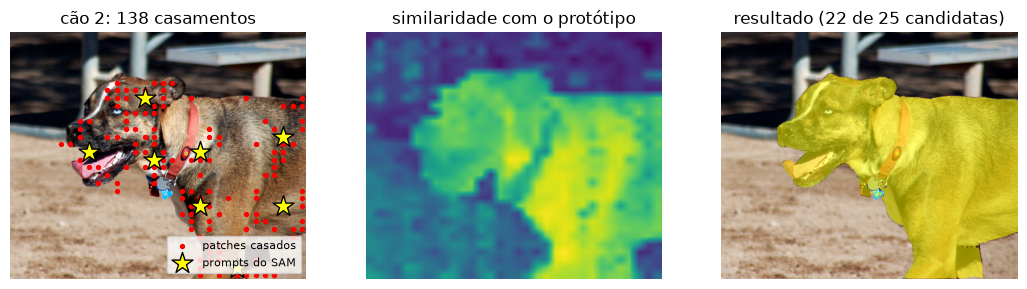

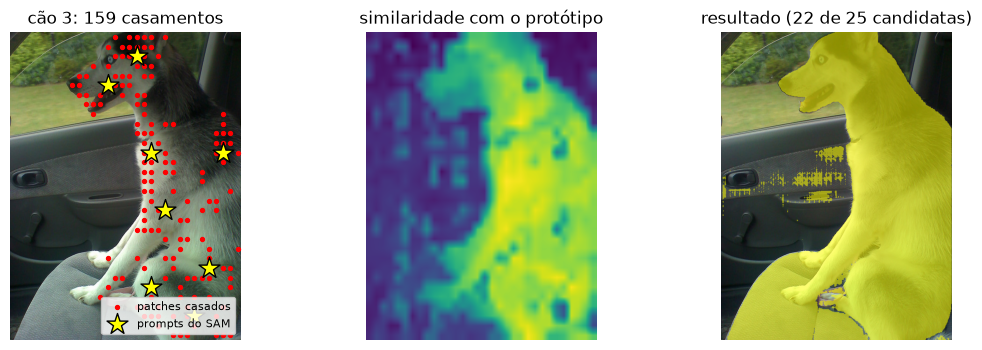

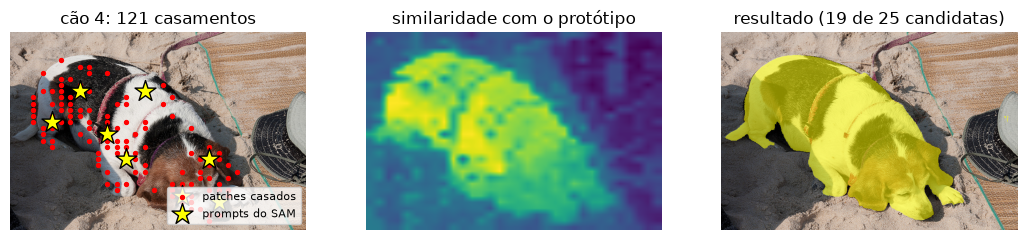

In [27]:
def patch_centers(idx, img):
    """Índices na grade G x G -> coordenadas (x, y), em pixels, do centro de cada patch."""
    W, H = img.size
    idx = idx.cpu().numpy()
    return np.stack([(idx % G + 0.5) * W / G, (idx // G + 0.5) * H / G], axis=1)


@torch.no_grad()
def matcher(f_ref, m_ref, tgt_img, n_clusters=8, keep=0.8, title=""):
    f_tgt = patch_features(tgt_img)
    W, H = tgt_img.size
    # 1-2. casamento bidirecional -> pontos no alvo
    pts = patch_centers(match_patches(f_ref, m_ref, f_tgt), tgt_img)
    # 3. k-means; o prompt de cada grupo é o ponto casado mais perto do centro do grupo
    km = KMeans(min(n_clusters, len(pts)), n_init=10, random_state=0).fit(pts)
    prompts = []
    for c, center in enumerate(km.cluster_centers_):
        P = pts[km.labels_ == c]
        prompts.append(P[((P - center) ** 2).sum(1).argmin()])
    # 4. máscaras candidatas: 3 por prompt + 1 com todos os prompts juntos
    E = sam_embed(tgt_img)
    cands = [m for p in prompts for m in sam_predict(E, points=[p])[0]]
    cands.append(sam_predict(E, points=prompts, multimask=False)[0][0])
    # 5. nota = similaridade média com o protótipo do objeto; junta as candidatas boas
    proto = F.normalize(f_ref[m_ref].mean(0), dim=0)
    heat = F.interpolate((f_tgt @ proto).view(1, 1, G, G), size=(H, W), mode="bilinear")[0, 0].cpu().numpy()
    scores = np.array([heat[m].mean() if m.any() else -1.0 for m in cands])
    final = np.any([m for m, s in zip(cands, scores) if s >= keep * scores.max()], axis=0)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(tgt_img)
    axes[0].scatter(*pts.T, s=8, c="red", label="patches casados")
    axes[0].scatter(*np.array(prompts).T, s=250, c="yellow", marker="*", edgecolor="k", label="prompts do SAM")
    axes[0].legend(loc="lower right", fontsize=8)
    axes[0].set_title(f"{title}: {len(pts)} casamentos")
    axes[1].imshow(heat, cmap="viridis")
    axes[1].set_title("similaridade com o protótipo")
    axes[2].imshow(tgt_img)
    axes[2].imshow(np.ma.masked_where(~final, final), alpha=0.55, cmap="autumn", vmin=0, vmax=1)
    axes[2].set_title(f"resultado ({(scores >= keep * scores.max()).sum()} de {len(cands)} candidatas)")
    for ax in axes:
        ax.axis("off")
    plt.show()
    return final


for name, img in targets.items():
    matcher(f_ref, m_ref, img, title=name)

Outra referência: a girafa do setup. Uma das imagens alvo tem **duas** girafas.

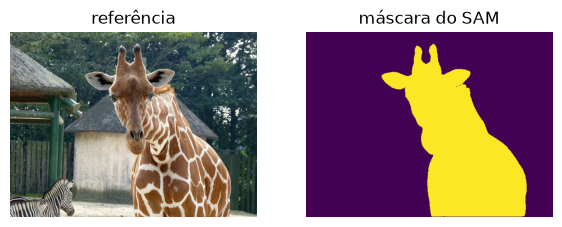

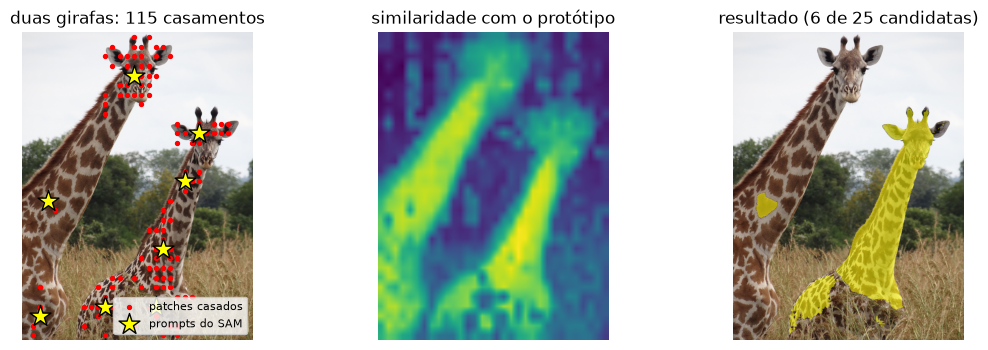

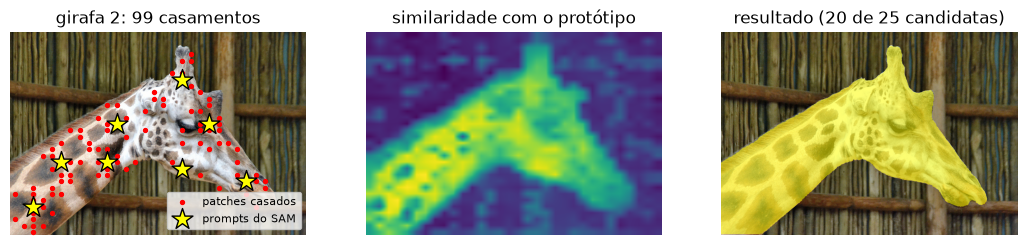

In [28]:
giraffe_mask = sam_predict(sam_embed(IMG["girafa"]), box=(194, 27, 574, 475), multimask=False)[0][0]
f_gir, m_gir = patch_features(IMG["girafa"]), mask_to_grid(giraffe_mask)
show([IMG["girafa"], giraffe_mask], ["referência", "máscara do SAM"])
for name, i in {"duas girafas": 79188, "girafa 2": 469652}.items():
    matcher(f_gir, m_gir, load_image(i), title=name)

**Pergunte-se:**
- Olhem os pontos casados (vermelhos): caem todos no animal? Onde estão os erros? O caminho de volta ajudou? (Troquem temporariamente o `match_patches` por uma versão só com a ida e comparem.)
- Na imagem com duas girafas, o resultado pega as duas? Que passo do pipeline é responsável por isso?
- Usem o cão de referência numa imagem de gato (`matcher(f_ref, m_ref, IMG["gato"])`). O que acontece? Por que o nosso Matcher não tem como dizer "não tem cão aqui"? Que regra vocês acrescentariam?
- Nada aqui foi treinado para segmentar cães. De onde vem cada parte do resultado: o que o DINOv2 fez e o que o SAM fez?

# Para ir além

Escolham um experimento, expliquem o que fizeram e compartilhem os resultados no [issue do GitHub](https://github.com/Erickslb/deep-learning-fgv-2026/issues), que todo mundo vê.

1. **Segmentação de partes (slide 108):** usem como referência só a **cabeça** do cão (uma das máscaras ambíguas do SAM, ou uma caixa menor) e rodem o Matcher nos outros cães. Ele encontra cabeças?
2. **Outro backbone no Matcher:** troquem o DINOv2 pelo DINO, MSN ou MAE da Parte 4 (os tokens de patch, `last_hidden_state[0, 1:]`, numa grade 14×14, com `G = 14` e imagens 224×224). Qual funciona melhor? Combina com a tabela da Parte 4?
3. **Resolução do ViT:** meçam a acurácia do ViT supervisionado (a cabeça do ImageNet não serve para o CIFAR: usem os protótipos da Parte 4) com as imagens em 224 e em 384, usando o TODO 2. E em 160, interpolando para uma grade **menor**?
4. **Segment everything:** passem para o SAM uma grade de pontos (por exemplo, 16×16 pontos, um prompt por vez) e fiquem com as máscaras de IoU previsto alto, sem repetir as que se sobrepõem muito.
5. **MAE fora da distribuição:** rodem o MAE numa foto de texto, num desenho ou num print de tela. O que ele "inventa" nos patches escondidos?